## Importando Bibliotecas e Carregando os Dados

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.preprocessing import StandardScaler

In [5]:
caminho_atual = Path(".").resolve()
df_train = pd.read_csv(caminho_atual.parent / "data" / "raw" / "train.csv", skipinitialspace=True)
df_test = pd.read_csv(caminho_atual.parent / "data" / "raw" / "test.csv", skipinitialspace=True)

print(f"Treino: {df_train.shape[0]} linhas e {df_train.shape[1]} colunas")
print(f"Teste:  {df_test.shape[0]} linhas e {df_test.shape[1]} colunas")

Treino: 712 linhas e 11 colunas
Teste:  179 linhas e 10 colunas


## 1. Padronização de Colunas e Correção de Inconsistências

- No `train.csv` a coluna de irmãos/cônjuges está como `siblings`, enquanto no `test.csv` está como `SibSp`. Padronizamos ambas para `SibSp`.
- Corrigimos os valores de `Fare > 513(maior valor no data/raw/titanic_raw.csv)` que perderam o ponto decimal e ficaram multiplicados por `1000`.

In [6]:
# Remove espaços extras caso o CSV tenha sido formatado no editor e padroniza siblings -> SibSp
df_train.columns = df_train.columns.str.strip()
df_test.columns = df_test.columns.str.strip()

for col in df_test.select_dtypes(include="str").columns:
    df_test[col] = df_test[col].str.strip().replace("", np.nan)

df_train = df_train.rename(columns={"siblings": "SibSp"})

print("Colunas Treino:", df_train.columns.tolist())
print("Colunas Teste: ", df_test.columns.tolist())

Colunas Treino: ['Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']
Colunas Teste:  ['Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']


In [7]:
df_train["Fare"] = df_train["Fare"].apply(lambda x: x / 1000 if x > 513 else x)
df_test["Fare"] = df_test["Fare"].apply(lambda x: x / 1000 if x > 513 else x)

print("Resumo de Fare após correção (Treino e Teste):")
resumo_fare = pd.DataFrame({
    "Treino": df_train["Fare"].describe(),
    "Teste": df_test["Fare"].describe()
}).round(2)
display(resumo_fare.T)

Resumo de Fare após correção (Treino e Teste):


,count,mean,std,min,25%,50%,75%,max
Treino,712.0,31.82,48.06,0.0,7.90,14.45,31.0,512.33
Teste,179.0,33.73,55.84,0.0,7.99,15.25,31.8,512.33


## 2. Feature Engineering

Criamos novos atributos com base nos padrões encontrados na EDA:
- `Title`: extraído de `Name` (separa faixa etária e gênero social, como `Master` para meninos e `Mr` para homens adultos).
- `family_size`, `is_alone` e `fare_per_person`: representam o tamanho do grupo familiar e o valor real pago por pessoa.
- `has_cabin` e `Deck`: indicam se o passageiro possuía cabine registrada e a letra do convés.

In [8]:
df_train["Title"] = df_train["Name"].str.extract(r" ([A-Za-z]+)\.", expand=False)
df_test["Title"] = df_test["Name"].str.extract(r" ([A-Za-z]+)\.", expand=False)

# Padroniza títulos equivalentes e agrupa os raros
mapa_titulos = {"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"}
df_train["Title"] = df_train["Title"].replace(mapa_titulos)
df_test["Title"] = df_test["Title"].replace(mapa_titulos)

titulos_principais = ["Mr", "Miss", "Mrs", "Master"]
df_train["Title"] = df_train["Title"].apply(lambda x: x if x in titulos_principais else "Rare")
df_test["Title"] = df_test["Title"].apply(lambda x: x if x in titulos_principais else "Rare")

contagem_titulos = pd.DataFrame({
    "Treino": df_train["Title"].value_counts(),
    "Teste": df_test["Title"].value_counts()
})
display(contagem_titulos)

,Treino,Teste
Title,,
Mr,412,105
Miss,144,41
Mrs,107,19
Master,31,9
Rare,18,5


In [9]:
df_train["family_size"] = df_train["SibSp"] + df_train["Parch"] + 1
df_test["family_size"] = df_test["SibSp"] + df_test["Parch"] + 1

df_train["is_alone"] = (df_train["family_size"] == 1).astype(int)
df_test["is_alone"] = (df_test["family_size"] == 1).astype(int)

df_train["fare_per_person"] = df_train["Fare"] / df_train["family_size"]
df_test["fare_per_person"] = df_test["Fare"] / df_test["family_size"]

display(df_train[["SibSp", "Parch", "family_size", "is_alone", "Fare", "fare_per_person"]].head())

,SibSp,Parch,family_size,is_alone,Fare,fare_per_person
0,1,0,2,0,7.2500,3.62500
1,1,0,2,0,71.2833,35.64165
2,0,0,1,1,7.9250,7.92500
3,1,0,2,0,53.1000,26.55000
4,0,0,1,1,8.4583,8.45830


In [10]:
df_train["has_cabin"] = df_train["Cabin"].notna().astype(int)
df_test["has_cabin"] = df_test["Cabin"].notna().astype(int)

df_train["Deck"] = df_train["Cabin"].str[0].fillna("Unknown")
df_test["Deck"] = df_test["Cabin"].str[0].fillna("Unknown")

# O Deck T possui apenas 1 registro de 1ª classe no treino e nenhum no teste, agrupamos no Deck A(Possui 80% da 1ª classe)
df_train["Deck"] = df_train["Deck"].replace({"T": "A"})
df_test["Deck"] = df_test["Deck"].replace({"T": "A"})

contagem_decks = pd.DataFrame({
    "Treino": df_train["Deck"].value_counts(),
    "Teste": df_test["Deck"].value_counts()
}).fillna(0).astype(int)
display(contagem_decks)

,Treino,Teste
Deck,,
A,15,1
B,34,13
C,41,18
D,26,7
E,29,3
F,11,2
G,4,0
Unknown,552,135


## 3. Tratamento de Valores Ausentes

- `Embarked`: possui apenas 2 nulos no treino, preenchemos com o porto mais frequente (`S`).
- `Age`: possui 137 nulos no treino e 40 no teste. Preenchemos usando a mediana da idade agrupada por `Pclass` e `Title` (calculada apenas no treino para evitar vazamento de dados).

In [11]:
nulos_antes = pd.DataFrame({
    "Nulos Treino": df_train.isna().sum(),
    "Nulos Teste": df_test.isna().sum()
})
display(nulos_antes[nulos_antes["Nulos Treino"] + nulos_antes["Nulos Teste"] > 0])

,Nulos Treino,Nulos Teste
Age,137,40.0
Cabin,552,135.0
Embarked,2,0.0


In [12]:
moda_embarked = df_train["Embarked"].mode()[0]
df_train["Embarked"] = df_train["Embarked"].fillna(moda_embarked)
df_test["Embarked"] = df_test["Embarked"].fillna(moda_embarked) # - caso o teste mude

print(f"Moda utilizada para Embarked: {moda_embarked}")
print("Nulos restantes em Embarked:", df_train["Embarked"].isna().sum(), df_test["Embarked"].isna().sum())

Moda utilizada para Embarked: S
Nulos restantes em Embarked: 0 0


In [13]:
medianas_idade = df_train.groupby(["Pclass", "Title"])["Age"].median()
print("Tabela de medianas de idade por Pclass e Title (calculada no treino):")
display(medianas_idade.unstack())

for (pclass, title), mediana in medianas_idade.items():
    mask_train = (df_train["Pclass"] == pclass) & (df_train["Title"] == title) & (df_train["Age"].isna())
    df_train.loc[mask_train, "Age"] = mediana
    
    mask_test = (df_test["Pclass"] == pclass) & (df_test["Title"] == title) & (df_test["Age"].isna())
    df_test.loc[mask_test, "Age"] = mediana

print("Nulos restantes em Age (Treino):", df_train["Age"].isna().sum())
print("Nulos restantes em Age (Teste): ", df_test["Age"].isna().sum())

Tabela de medianas de idade por Pclass e Title (calculada no treino):


Title,Master,Miss,Mr,Mrs,Rare
Pclass,,,,,
1,2.46,30.0,40.0,39.0,49.0
2,1.00,24.0,30.0,33.5,51.0
3,5.00,18.0,27.0,31.0,NaN


Nulos restantes em Age (Treino): 0
Nulos restantes em Age (Teste):  0


## 4. Tratamento de Variáveis Categóricas e Seleção de Colunas

- Removemos `Name`, `Ticket` e `Cabin`, pois já extraímos os atributos relevantes delas.
- Mapeamos `Sex` para `0` (`male`) e `1` (`female`).
- Aplicamos One-Hot Encoding nas variáveis nominais (`Embarked`, `Title` e `Deck`).

In [14]:
colunas_remover = ["Name", "Ticket", "Cabin"]
df_train = df_train.drop(columns=colunas_remover)
df_test = df_test.drop(columns=colunas_remover)

mapa_sex = {"male": 0, "female": 1}
df_train["Sex"] = df_train["Sex"].map(mapa_sex)
df_test["Sex"] = df_test["Sex"].map(mapa_sex)

display(df_train.head())

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,Title,family_size,is_alone,fare_per_person,has_cabin,Deck
0,0,3,0,22.0,1,0,7.2500,S,Mr,2,0,3.62500,0,Unknown
1,1,1,1,38.0,1,0,71.2833,C,Mrs,2,0,35.64165,1,C
2,1,3,1,26.0,0,0,7.9250,S,Miss,1,1,7.92500,0,Unknown
3,1,1,1,35.0,1,0,53.1000,S,Mrs,2,0,26.55000,1,C
4,0,3,0,27.0,0,0,8.4583,Q,Mr,1,1,8.45830,0,Unknown


In [15]:
colunas_categoricas = ["Embarked", "Title", "Deck"]
df_train = pd.get_dummies(df_train, columns=colunas_categoricas, dtype=int)
df_test = pd.get_dummies(df_test, columns=colunas_categoricas, dtype=int)

# Alinha as colunas do teste com as features do treino
colunas_features = [col for col in df_train.columns if col != "Survived"]
df_test = df_test.reindex(columns=colunas_features, fill_value=0)

print(f"Dimensões finais Treino: {df_train.shape}")
print(f"Dimensões finais Teste:  {df_test.shape}")
display(df_train.head())

Dimensões finais Treino: (712, 27)
Dimensões finais Teste:  (179, 26)


,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,family_size,is_alone,fare_per_person,...,Title_Mrs,Title_Rare,Deck_A,Deck_B,Deck_C,Deck_D,Deck_E,Deck_F,Deck_G,Deck_Unknown
0,0,3,0,22.0,1,0,7.2500,2,0,3.62500,...,0,0,0,0,0,0,0,0,0,1
1,1,1,1,38.0,1,0,71.2833,2,0,35.64165,...,1,0,0,0,1,0,0,0,0,0
2,1,3,1,26.0,0,0,7.9250,1,1,7.92500,...,0,0,0,0,0,0,0,0,0,1
3,1,1,1,35.0,1,0,53.1000,2,0,26.55000,...,1,0,0,0,1,0,0,0,0,0
4,0,3,0,27.0,0,0,8.4583,1,1,8.45830,...,0,0,0,0,0,0,0,0,0,1


## 5. Avaliação da Relevância das Variáveis

,Correlação com Survived
Sex,0.549
has_cabin,0.351
Title_Mrs,0.347
Title_Miss,0.336
Fare,0.275
fare_per_person,0.222
Embarked_C,0.180
Deck_D,0.170
Deck_B,0.162
Deck_E,0.159


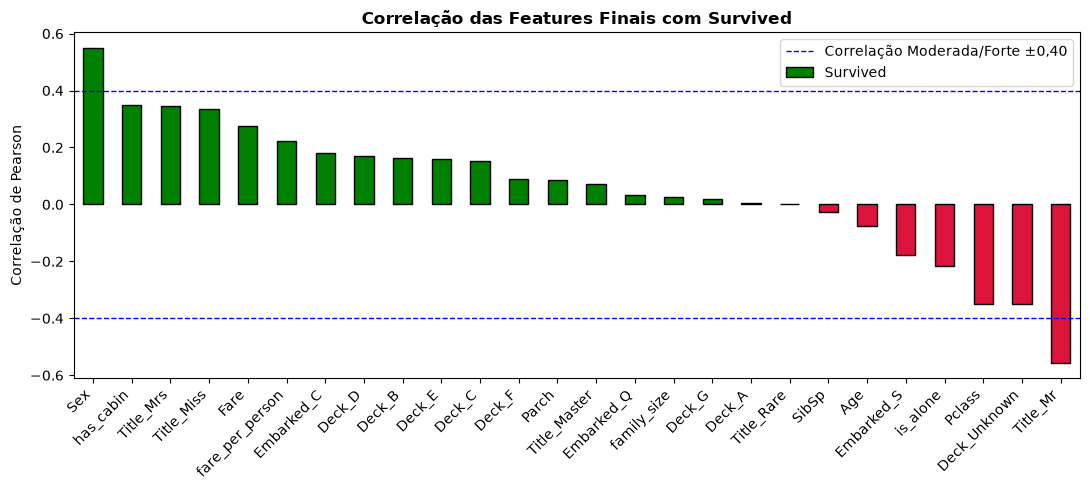

In [16]:
correlacoes = df_train.corr()["Survived"].drop("Survived").sort_values(ascending=False) 
display(correlacoes.to_frame(name="Correlação com Survived").round(3))

plt.figure(figsize=(11, 5))
cores = ["green" if v > 0 else "crimson" for v in correlacoes.values]
correlacoes.plot(kind="bar", color=cores, edgecolor="black")
plt.title("Correlação das Features Finais com Survived", fontweight="bold")
plt.ylabel("Correlação de Pearson")
plt.axhline(0.40, color="blue", linestyle="--", linewidth=1, label="Correlação Moderada/Forte ±0,40")
plt.axhline(-0.40, color="blue", linestyle="--", linewidth=1)
plt.legend()
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show() 

## 6. Padronização e Salvamento dos Dados Processados

- Modelos de árvores (Decision Tree, Random Forest, Gradient Boosting) não dependem de padronização de escala.
- Para permitir testes justos também com modelos sensíveis à escala (como Regressão Logística, KNN ou SVM), geramos uma versão padronizada com `StandardScaler` ajustado somente no conjunto de treino.

In [17]:
pasta_processed = caminho_atual.parent / "data" / "processed"
pasta_processed.mkdir(parents=True, exist_ok=True)

df_train.to_csv(pasta_processed / "train_processed.csv", index=False)
df_test.to_csv(pasta_processed / "test_processed.csv", index=False)

colunas_continuas = ["Age", "SibSp", "Parch", "Fare", "family_size", "fare_per_person"]
scaler = StandardScaler()

df_train_scaled = df_train.copy()
df_test_scaled = df_test.copy()

df_train_scaled[colunas_continuas] = scaler.fit_transform(df_train[colunas_continuas])
df_test_scaled[colunas_continuas] = scaler.transform(df_test[colunas_continuas])

df_train_scaled.to_csv(pasta_processed / "train_scaled.csv", index=False)
df_test_scaled.to_csv(pasta_processed / "test_scaled.csv", index=False)

print("Datasets salvos com sucesso em data/processed/:")
print("- train_processed.csv:", df_train.shape)
print("- test_processed.csv: ", df_test.shape)
print("- train_scaled.csv:   ", df_train_scaled.shape)
print("- test_scaled.csv:    ", df_test_scaled.shape)

Datasets salvos com sucesso em data/processed/:
- train_processed.csv: (712, 27)
- test_processed.csv:  (179, 26)
- train_scaled.csv:    (712, 27)
- test_scaled.csv:     (179, 26)


#### Variável de contagem vs. Modelos de Distância (KNN, SVM, Regressão Logística)

`SibSp` e `Parch` são variáveis discretas (números inteiros de contagem: 0, 1, 2... até 8).

Se formos rodar um modelo como KNN (que calcula distância euclidiana) ou Regressão Logística / SVM com regularização:

As variáveis resultantes do One-Hot Encoding (Sex, Embarked_S, Title_Mr, etc.) variam apenas entre 0 e 1.
Um passageiro com SibSp = 8 teria uma diferença de distância de até 8 unidades em relação a quem tem 0, pesando 8 vezes mais no cálculo de distância do que o passageiro ser homem ou mulher (Sex = 0 vs 1), o que distorce o algoritmo.
O StandardScaler apenas centraliza a média em 0 e ajusta o desvio padrão para 1, colocando todas as grandezas numéricas na mesma ordem de grandeza das variáveis binárias.

#### Para modelos de Árvore (Decision Tree, Random Forest, XGBoost)

Para os modelos baseados em árvores, isso não faz diferença alguma:

Árvores não calculam distância nem multiplicam por pesos (
𝑤
⋅
𝑥
w⋅x). Elas apenas encontram pontos de corte (ex: SibSp <= 2.5 ou Fare <= 31.0).
Por isso criamos os dois arquivos:
train_processed.csv: mantém SibSp, Parch, family_size como inteiros originais (0, 1, 2...), perfeito e intuitivo para árvores de decisão.
train_scaled.csv: feito exclusivamente caso você queira comparar árvores contra KNN, SVM ou Regressão Logística.

In [18]:
display(df_train.head())
display(df_train_scaled.head())

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,family_size,is_alone,fare_per_person,...,Title_Mrs,Title_Rare,Deck_A,Deck_B,Deck_C,Deck_D,Deck_E,Deck_F,Deck_G,Deck_Unknown
0,0,3,0,22.0,1,0,7.2500,2,0,3.62500,...,0,0,0,0,0,0,0,0,0,1
1,1,1,1,38.0,1,0,71.2833,2,0,35.64165,...,1,0,0,0,1,0,0,0,0,0
2,1,3,1,26.0,0,0,7.9250,1,1,7.92500,...,0,0,0,0,0,0,0,0,0,1
3,1,1,1,35.0,1,0,53.1000,2,0,26.55000,...,1,0,0,0,1,0,0,0,0,0
4,0,3,0,27.0,0,0,8.4583,1,1,8.45830,...,0,0,0,0,0,0,0,0,0,1


,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,family_size,is_alone,fare_per_person,...,Title_Mrs,Title_Rare,Deck_A,Deck_B,Deck_C,Deck_D,Deck_E,Deck_F,Deck_G,Deck_Unknown
0,0,3,0,-0.549999,0.478335,-0.466183,-0.511601,0.073412,0,-0.445006,...,0,0,0,0,0,0,0,0,0,1
1,1,1,1,0.639499,0.478335,-0.466183,0.821722,0.073412,0,0.404499,...,1,0,0,0,1,0,0,0,0,0
2,1,3,1,-0.252624,-0.465084,-0.466183,-0.497546,-0.556339,1,-0.330913,...,0,0,0,0,0,0,0,0,0,1
3,1,1,1,0.416468,0.478335,-0.466183,0.443103,0.073412,0,0.163268,...,1,0,0,0,1,0,0,0,0,0
4,0,3,0,-0.178281,-0.465084,-0.466183,-0.486442,-0.556339,1,-0.316763,...,0,0,0,0,0,0,0,0,0,1
